In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt #for igures
%matplotlib inline
import matplotlib.animation as animation


In [2]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
len(words)


32033

In [16]:
#built wocabulary of characters and mappings to from integers 
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.']= 0
itos={i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [17]:

# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words:
  
  #print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    #print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

In [40]:

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
w1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
w2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, w1, b1, w2, b2]
for p in parameters:
    p.requires_grad = True

In [19]:
lre=torch.linspace(-3, 0 ,1000)
lrs= 10**lre
lrs

tensor([0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012,
        0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0013, 0.0013, 0.0013,
        0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0014,
        0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014,
        0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015,
        0.0015, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016,
        0.0016, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017,
        0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0019,
        0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0020, 0.0020,
        0.0020, 0.0020, 0.0020, 0.0020, 0.0020, 0.0021, 0.0021, 0.0021, 0.0021,
        0.0021, 0.0021, 0.0021, 0.0022, 

In [41]:
lrt=[]
lri = []
lossi = []
for i in range (1000):
    # mini batch costruct
    ix = torch.randint(0, X.shape[0], (32,))

    #Forwardpass
    emb=C[X[ix]]#[32,3,2]
    h=torch.tanh(emb.view(-1,6)@ w1 + b1)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, Y[ix])
    # print (loss.item())#bachs lost

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    #update
    lr = lrs[i]
    #lr = 10**-1
    #lr = 0.01
    for p in parameters:
        p.data += -lr *p.grad
    #track stats
    lrt.append(lr)
    lri.append(lre[i])
    lossi.append(loss.item())

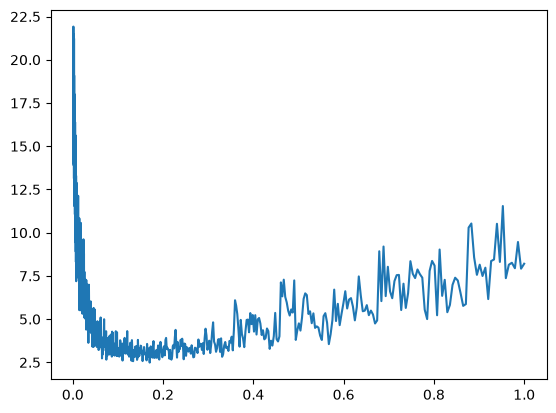

In [43]:
plt.plot(lrt , lossi )

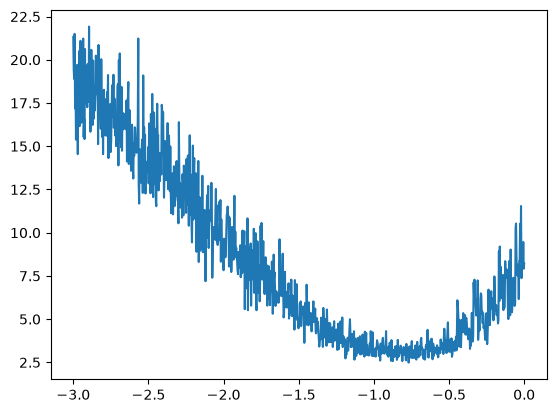

In [44]:
plt.plot(lri , lossi ) 
#exp of the lerning rate 

In [27]:
#training split - dev/validation split - test split
# %80 - %10 - %10

In [45]:
# buil the dataset 
def built_dataset(words):
    block_size= 3 #context lenght :how many charakter do we take to predict next one 
    X , Y = [] , []
    for w in words:
        contex = [0] * block_size
        for ch in w + '.' :
            ix =stoi[ch]
            X.append(contex)
            Y.append(ix)
            contex=contex[1:]+[ix]#crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X,Y
import random
random.seed(42)
random.shuffle(words)
n1 = int (0.8 * len(words))
n2 = int (0.9 * len(words))

Xtr,Ytr = built_dataset(words[:n1])
Xdev,Ydev = built_dataset(words[n1:n2])
Xte, Yte = built_dataset(words[n2:])

torch.Size([182437, 3]) torch.Size([182437])
torch.Size([22781, 3]) torch.Size([22781])
torch.Size([22928, 3]) torch.Size([22928])


In [104]:
#lets enlarge our network to improve modal capabilities
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
w1 = torch.randn((6, 200), generator=g)
b1 = torch.randn(200, generator=g)
w2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, w1, b1, w2, b2]
for p in parameters:
    p.requires_grad = True

In [105]:
stepi=[]
lossi =[]
for i in range (10000):
    # mini batch costruct
    ix = torch.randint(0, Xtr.shape[0], (64,))#batch size ascended -> search stabilized

    #Forwardpass
    emb=C[Xtr[ix]]
    h=torch.tanh(emb.view(-1,6)@ w1 + b1)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    # print (loss.item())#bachs lost

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    #update
    lr = 0.01
    for p in parameters:
        p.data += -lr *p.grad
    stepi.append(i)
    lossi.append(loss.item())

    if i % 10 == 0 :
        save_embedding(i)#before run this cell you should run this funcion which in  5 cell above


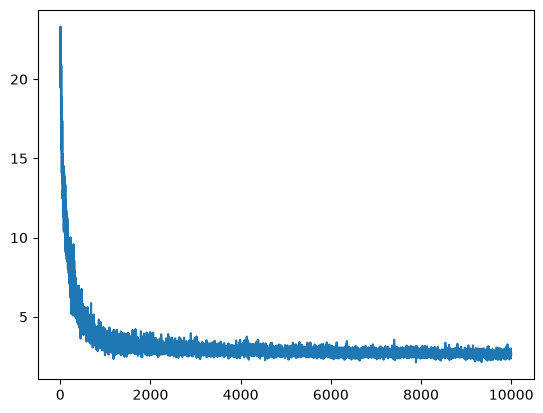

In [106]:
plt.plot(stepi,lossi)

In [107]:

print(loss.item())

2.6245951652526855


In [108]:
emb=C[Xtr]
h=torch.tanh(emb.view(-1,6)@ w1 + b1) 
logits = h @ w2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.6511, grad_fn=<NllLossBackward0>)

In [109]:
emb=C[Xdev]
h=torch.tanh(emb.view(-1,6)@ w1 + b1) 
logits = h @ w2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.6638, grad_fn=<NllLossBackward0>)

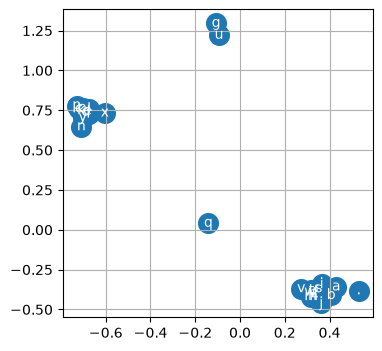

In [110]:
plt.figure(figsize=(4,4))
plt.scatter(C[:,0].data,C[:,1].data, s=200)
for i in range (C.shape[0]):
    plt.text(C[i,0].item(),C[i,1].item(), itos[i], ha= "center", va ="center", color='white')
plt.grid('minor')

In [ ]:
#run this cell only once before the train
C_snapshots = []

def save_embedding(step):
    # C'nin o anki halini kopyala (gradyan takibi olmadan)
    C_snapshots.append((step, C.detach().clone()))

def make_embedding_gif(snapshots, path='embedding.gif', fps=20, max_frames=200):
    # cok fazla kare varsa aralarindan esit aralikli sec
    if len(snapshots) > max_frames:
        idx = torch.linspace(0, len(snapshots) - 1, max_frames).long()
        snapshots = [snapshots[i] for i in idx]

    # tum karelerde ayni eksen sinirlari olsun ki hareket gorunsun
    allC = torch.stack([c for _, c in snapshots])
    xmin, xmax = allC[:, :, 0].min().item(), allC[:, :, 0].max().item()
    ymin, ymax = allC[:, :, 1].min().item(), allC[:, :, 1].max().item()
    pad = 0.1 * max(xmax - xmin, ymax - ymin)

    fig, ax = plt.subplots(figsize=(6, 6))
    def draw(k):
        step, Ck = snapshots[k]
        ax.clear()
        ax.scatter(Ck[:, 0], Ck[:, 1], s=100)
        for i in range(Ck.shape[0]):
            ax.text(Ck[i, 0].item(), Ck[i, 1].item(), itos[i], ha="center", va="center", color='white')
        ax.set_xlim(xmin - pad, xmax + pad)
        ax.set_ylim(ymin - pad, ymax + pad)
        ax.grid()
        ax.set_title(f'step {step}')

    anim = animation.FuncAnimation(fig, draw, frames=len(snapshots))
    anim.save(path, writer=animation.PillowWriter(fps=fps))
    plt.close(fig)
    print(f'{path} kaydedildi ({len(snapshots)} kare)')


embedding.gif kaydedildi (200 kare)


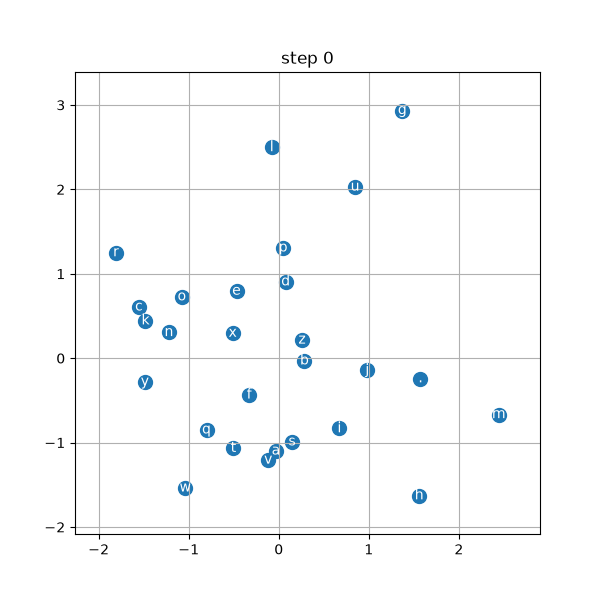

In [112]:
make_embedding_gif(C_snapshots)

from IPython.display import Image
Image(filename='embedding.gif')


In [114]:

context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 3, 2])

In [115]:

# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ w1 + b1)
      logits = h @ w2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

carlah.
aaj.
hlvuhk.
mrr.
reety.
halassne.
rahnen.
dhesyrc.
kaeei.
nel.
kia.
ceriiv.
kalein.
hham.
join.
qiijn.
srlin.
alvanbi.
wazero.
dearyni.


In [129]:
# forcing hidden layer nuerons experiment
gn = torch.Generator().manual_seed(42) 
# change this seed to force different neurons and see how each one affects the generated names
#result may longer or shorter or some chars may be dominant in the produced word
forced = torch.randperm(w1.shape[1], generator=gn)[:3]
print('forced neuron:', forced.tolist())

def sample_names(n=20, forced=None, value=1.0, max_len=30, seed=2147483647 + 10):
    g = torch.Generator().manual_seed(seed)
    names = []
    with torch.no_grad():
        for _ in range(n):
            out = []
            context = [0] * block_size # initialize with all ...
            while True:
                emb = C[torch.tensor([context])] # (1,block_size,d)
                h = torch.tanh(emb.view(1, -1) @ w1 + b1)
                if forced is not None:
                    h[:, forced] = value # force these  neuron
                logits = h @ w2 + b2
                probs = F.softmax(logits, dim=1)
                ix = torch.multinomial(probs, num_samples=1, generator=g).item()
                context = context[1:] + [ix]
                out.append(ix)
                if ix == 0 or len(out) >= max_len:
                    break
            names.append(''.join(itos[i] for i in out))
    return names

normal = sample_names()
zorlu = sample_names(forced=forced)
print(f'{"normal":20s} forced')
for a, b in zip(normal, zorlu):
    print(f'{a:20s} {b}')


forced neuron: [142, 56, 198]
normal               forced
carlah.              no.
aaj.                 mii.
hlvuhk.              mmi.
mrr.                 mm.
reety.               mii.
halassne.            mln.
rahnen.              mim.
dhesyrc.             mmnn.
kaeei.               mon.
nel.                 mom.
kia.                 bnnn.
ceriiv.              mmn.
kalein.              mim.
hham.                mon.
join.                iin.
qiijn.               mmni.
srlin.               mcmmiin.
alvanbi.             m.
wazero.              nm.
dearyni.             m.
